# Edge orange-fruit disease diagnosis: YOLOv8 detection + HSL color-spectrum classification

Reproduction of the executable inference branch of:
**"An edge computing wireless sensor network for diagnosing orange fruit disease"**
(DOI: [10.1007/s10586-024-04999-y](https://doi.org/10.1007/s10586-024-04999-y), *Cluster Computing* 28(5), 2025).

- **Author code** (MIT License, © 2024 Arman Foroughi): [ArmanForoughi/Diagnosing-types-of-orange-fruit-diseases-by-image-processing-and-YOLOv8](https://github.com/ArmanForoughi/Diagnosing-types-of-orange-fruit-diseases-by-image-processing-and-YOLOv8), pinned commit `94a949622ec22d96a3033fc73c41390dbe6dfc14`, file `orange fruit disease.py`.
- **Scope**: run the author's published per-image inference branch — YOLOv8 fruit detection (`yolo_orange.pt`, conf 0.6), 150×150 crop, two HSL orange masks with a majority-filter noise removal, and pixel-count diagnosis into **healthy / canker / black spot / melanosis** — on a minimal batch of the repository's own sample images.
- **Out of scope**: the Raspberry Pi + Zigbee/LoRa WSN hardware deployment, the 97-image benchmark accuracy claims, model training (no training script in the repository), and email alerting (present but commented out with placeholder credentials in the author's code).
- **Execution status**: this notebook is delivered with saved outputs from a fresh Google Colab **CPU** runtime.

**日本語**: 論文「エッジコンピューティング無線センサネットワークによるオレンジ果実病害の診断」の推論部分を再現します。著者公開コード（MIT、commit `94a9496`）の `orange fruit disease.py` のうち、YOLOv8 検出（`yolo_orange.pt`、conf 0.6）→150×150 クロップ→HSL オレンジマスク＋ノイズ除去→画素数による healthy / canker / black spot / melanosis 診断、をリポジトリ同梱のサンプル画像の最小バッチで実行します。WSN ハードウェア構成・97 枚ベンチマーク・学習・メール警告は範囲外です。

## Runtime selection and how to run

**Select a CPU runtime** (Runtime → Change runtime type → CPU). No GPU is required: the detector is a small YOLOv8 checkpoint (~22.5 MB) and the color analysis runs on 150×150 crops; everything here runs in seconds per image on CPU. A GPU runtime would also work (ultralytics auto-selects the device) but is not required.

Click **Runtime → Run all**. Expected end-to-end time is a few minutes; total downloads are ~23 MB (weights) plus four sample images (≈0.5 MB).

**Adaptation notice**: the author's script is a Raspberry-Pi daemon (`while True` loop over `pic_camera/`, `cv2.imshow` windows, disabled e-mail alert). This notebook keeps every scientific operation identical but (1) runs **one pass** over a simulated capture batch instead of the hourly loop, (2) renders with matplotlib instead of `cv2.imshow` because Colab is headless, and (3) leaves e-mail sending disabled exactly as published. No thresholds, masks, or decision logic were changed.

**日本語**: CPU ランタイムを選択して「ランタイム → すべてのセルを実行」してください。GPU は不要です。著者コードは Raspberry Pi 常駐ループ＋`cv2.imshow` 表示ですが、本ノートブックは科学的手順を一切変えずに、1 回のみのバッチ実行・matplotlib 描画・メール無効化（著者コードのまま）に置き換えただけのヘッドレス Adaptation です。

## 1. Environment setup

We install `ultralytics` (the YOLOv8 framework the author's script imports) and print the versions actually used by this run. `opencv-python`, `numpy`, `matplotlib` and `torch` are already provided by the Colab image; we verify rather than reinstall them.

**日本語**: 著者スクリプトが import する `ultralytics` をインストールし、実行時に使ったバージョンを表示します。cv2/numpy/matplotlib/torch は Colab 画像に同梱のものを確認のみで使用します。

In [ ]:
%pip install -q ultralytics

import torch, cv2, numpy as np, matplotlib
import ultralytics
print("torch      :", torch.__version__)
print("ultralytics:", ultralytics.__version__)
print("opencv     :", cv2.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("CUDA available (informational; CPU is sufficient):", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


torch      : 2.11.0+cpu
ultralytics: 8.4.189
opencv     : 5.0.0
numpy      : 2.1.3
matplotlib : 3.10.0
CUDA available (informational; CPU is sufficient): False


## 2. Acquire the pinned weights and sample images (inside Colab only)

Everything is downloaded from the author repository at the pinned commit via `raw.githubusercontent.com`. Each file is verified against its **Git blob SHA-1** (`sha1("blob <size>\0" + bytes)`) taken from the GitHub tree of commit `94a9496`, so a wrong or truncated download cannot pass silently. The four images (`Healthy (17).jpg`, `c19.jpg`, `m15.jpg`, `b29.jpg`) are a deterministic one-per-inferred-class batch; the `c/b/m/Healthy` filename prefixes are **inferred from filenames only** (the repository documents no class mapping) and are used as informal context, never as ground truth.

**日本語**: 重みとサンプル画像を固定コミットの raw URL から取得し、Git blob SHA-1 で完全性を検証します。画像 4 枚はファイル名の接頭辞から推定したクラスを 1 枚ずつ選んだ最小バッチであり（リポジトリにクラス対応の文書はない）、あくまで参考情報です。

In [ ]:
import hashlib, io, urllib.request
from pathlib import Path

COMMIT = "94a949622ec22d96a3033fc73c41390dbe6dfc14"
REPO = "ArmanForoughi/Diagnosing-types-of-orange-fruit-diseases-by-image-processing-and-YOLOv8"
BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"

# path -> (expected size in bytes, expected Git blob SHA-1)
FILES = {
    "yolo_orange.pt": (22520409, "9a582785a0d69cd042f3392617edce93b2828a79"),
    "datasets for network/Healthy (17).jpg": (89263, "9fced3466074e71398fdc06ddf9920ce0b32ce13"),
    "datasets for network/c19.jpg": (205885, "c896a56693f9c08d565aafb21d527663ff732c0a"),
    "datasets for network/m15.jpg": (38159, "640c1c1e452dd5a1ad5b77818c8507651abd11a2"),
    "datasets for network/b29.jpg": (127460, "5c9a2e6b1f277edcb55049462a034c77e9ce6b5a"),
}

def fetch(rel_path, expected_size, expected_sha):
    url = f"{BASE}/{urllib.request.quote(rel_path)}"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=120) as r:
                data = r.read()
            break
        except Exception as e:
            if attempt == 2:
                raise RuntimeError(f"download failed after 3 tries: {url}: {e}")
    assert len(data) == expected_size, f"{rel_path}: size {len(data)} != {expected_size}"
    sha = hashlib.sha1(b"blob %d\x00" % expected_size + data).hexdigest()
    assert sha == expected_sha, f"{rel_path}: blob sha {sha} != {expected_sha}"
    return data

img_dir = Path("/content/pic_camera"); img_dir.mkdir(exist_ok=True)
weights_path = Path("/content/yolo_orange.pt")
for rel, (size, sha) in FILES.items():
    data = fetch(rel, size, sha)
    dest = weights_path if rel == "yolo_orange.pt" else img_dir / Path(rel).name
    dest.write_bytes(data)
    print(f"OK  {rel}  {len(data):,} bytes  blob sha1 verified")

# Guard: reject an accidental Git LFS pointer text file.
assert weights_path.read_bytes()[:2] != b"ve", "unexpected text payload for weights"
print("weights path:", weights_path)

OK  yolo_orange.pt  22,520,409 bytes  blob sha1 verified
OK  datasets for network/Healthy (17).jpg  89,263 bytes  blob sha1 verified


OK  datasets for network/c19.jpg  205,885 bytes  blob sha1 verified
OK  datasets for network/m15.jpg  38,159 bytes  blob sha1 verified


OK  datasets for network/b29.jpg  127,460 bytes  blob sha1 verified
weights path: /content/yolo_orange.pt


## 3. Input preview

We display the four sample images exactly as downloaded (BGR → RGB for matplotlib). These are the repository's own sample photographs for the 97-image benchmark, reduced here to one image per inferred disease class.

**日本語**: ダウンロードした 4 枚のサンプル画像をそのまま表示します（リポジトリ同梱のベンチマーク用写真、推定クラスごとに 1 枚）。

capture batch (simulating pic_camera/): ['Healthy (17).jpg', 'b29.jpg', 'c19.jpg', 'm15.jpg']


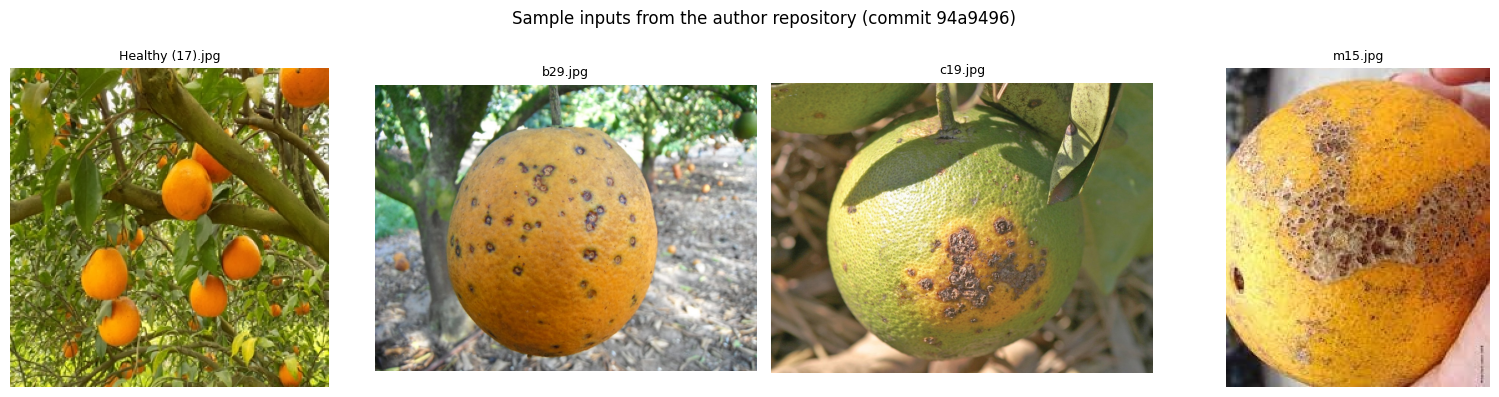

In [ ]:
import matplotlib.pyplot as plt

image_files = sorted(p.name for p in img_dir.iterdir() if p.suffix.lower() in {".jpg", ".png", ".jpeg"})
print("capture batch (simulating pic_camera/):", image_files)

fig, axes = plt.subplots(1, len(image_files), figsize=(4 * len(image_files), 4))
for ax, name in zip(axes, image_files):
    bgr = cv2.imread(str(img_dir / name))
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.suptitle("Sample inputs from the author repository (commit 94a9496)")
plt.tight_layout(); plt.show()

## 4. Author's algorithm — verbatim port (part 1)

The cell below copies the author's `remove_noise` majority filter and all color thresholds **exactly** from `orange fruit disease.py` (lines 18–27 and 63–95 at commit `94a9496`). Key faithful details that are easy to "fix" by mistake — and therefore deliberately kept as published:

- `mask_blackspot` is computed on the **BGR crop** `img_box`, not on the HLS image (author's line 98).
- The two orange masks are summed as `uint8` (`mask1 + mask2`, author's line 71).
- The `GaussianBlur` result is computed but never used by the author's script; it is kept for fidelity.
- The healthy/diseased decision re-uses the pre- and post-noise-removal orange mask counts with the 650-pixel threshold (author's line 107).

**日本語**: 著者の `remove_noise` 多数決フィルタと全しきい値を原文のまま移植します。black spot だけ BGR 画像に適用、オレンジマスクは uint8 加算、GaussianBlur は計算するだけ（著者コードのまま）、healthy 判定は 650 画素しきい値、という原文の細部を意図的に保持しています。

In [ ]:
# Verbatim port from "orange fruit disease.py" @ 94a9496 (MIT, Arman Foroughi)

def remove_noise(gray, num):
    # author's lines 18-27: per-pixel majority vote in a (2*num)x(2*num) window
    Y, X = gray.shape
    nearest_neigbours = [[
        np.argmax(
            np.bincount(
                gray[max(i - num, 0):min(i + num, Y),
                    max(j - num, 0):min(j + num, X)].ravel()))
        for j in range(X)] for i in range(Y)]
    result = np.array(nearest_neigbours, dtype=np.uint8)
    return result

# author's lines 63-69: two orange HLS ranges (H, L, S)
LOWER_ORANGE1 = np.array([0, 100, 110]);   UPPER_ORANGE1 = np.array([35, 200, 255])
LOWER_ORANGE2 = np.array([220, 100, 80]);  UPPER_ORANGE2 = np.array([255, 200, 255])

# author's lines 83-95: disease thresholds; black spot is applied to BGR!
LOWER_CANKER    = np.array([2, 50, 30],  dtype="uint8"); UPPER_CANKER    = np.array([41, 180, 100], dtype="uint8")
LOWER_BLACKSPOT = np.array([0, 0, 0],    dtype="uint8"); UPPER_BLACKSPOT = np.array([140, 90, 140], dtype="uint8")
LOWER_MELANOSIS = np.array([5, 60, 50],  dtype="uint8"); UPPER_MELANOSIS = np.array([20, 180, 130], dtype="uint8")

HEALTHY_PIXEL_DROP = 650  # author's line 107
CONF = 0.6                # author's line 47

## 5. Author's inference branch — verbatim port (part 2)

This function mirrors the author's per-image `for` loop (lines 46–131): YOLOv8 predict at conf 0.6, crop each box, resize to 150×150, blur (unused, kept), HLS conversion, orange masks + noise removal, disease counts, and the published decision. Only two things change: instead of `cv2.imshow` we return the arrays for matplotlib rendering, and instead of printing only, we collect structured records for the results table. The author's diagnostic prints (orange-mask counts) and the full treatment messages are preserved verbatim.

**日本語**: 著者の画像ごとのループ（46–131 行）をそのまま関数化したものです。`cv2.imshow` を配列返却に、print を記録収集に変えただけで、判定文と治療メッセージも原文どおりです。

In [ ]:
from ultralytics import YOLO

TREATMENTS = {
    "Canker": "is spoiled. is Canker disease is a skin and bacterial disease. The disease causes the branches to dry. To prevent this white paint be applied evenly to the main trunk of the tree. To treat this disease When 70% of the leaves have fallen, Bordofix poison is used after the formation of petals and fruits. In addition, to eliminate the disease with a knife, the affected part was pruned in winter in dry weather",
    "black spot": "is spoiled. is black spot. Treatments with guazatine or imazalil decrease the viability of the pathogen in black spot lesions. Fungicides such as strobilurins, dithiocarbamates and benzimidazoles are also efficient against the fungus, but resistances have also developed in many areas",
    "melanuses": "is spoiled. is melanuses. Protectant copper sprays are the only product registered for melanose control. timing of spray applications is very important. With Washington navel and Valencia oranges the spray should be applied at full petal fall.",
}

model = YOLO(str(weights_path))

def diagnose_image(path):
    # author's lines 46-131, per image; returns one record per detected box
    records = []
    results = model.predict(str(path), conf=CONF)
    img = cv2.imread(str(path))
    for result in results:
        boxes = result.boxes
        if boxes.cls.size()[0] != 0:
            for i, box in enumerate(boxes):
                x1, y1, x2, y2 = (int(v) for v in box.xyxy[0])
                img_box = img[y1:y2, x1:x2]
                img_box = cv2.resize(img_box, (150, 150))
                blur = cv2.GaussianBlur(img_box, (21, 21), 0)  # computed but unused, as published
                hsl = cv2.cvtColor(img_box, cv2.COLOR_BGR2HLS)

                mask1 = cv2.inRange(hsl, LOWER_ORANGE1, UPPER_ORANGE1)
                mask2 = cv2.inRange(hsl, LOWER_ORANGE2, UPPER_ORANGE2)
                mask_orenge_color = mask1 + mask2                      # author line 71 (uint8 add)
                mask_remove_noise = remove_noise(mask_orenge_color, 10)
                output_hsl = cv2.bitwise_and(hsl, hsl, mask=mask_remove_noise)

                mask_1 = cv2.inRange(output_hsl, LOWER_ORANGE1, UPPER_ORANGE1)
                mask_2 = cv2.inRange(output_hsl, LOWER_ORANGE2, UPPER_ORANGE2)
                mask_out = mask_1 + mask_2                             # author line 81

                count_canker    = cv2.countNonZero(cv2.inRange(hsl, LOWER_CANKER, UPPER_CANKER))
                count_blackspot = cv2.countNonZero(cv2.inRange(img_box, LOWER_BLACKSPOT, UPPER_BLACKSPOT))  # BGR, author line 98
                count_melanuses = cv2.countNonZero(cv2.inRange(hsl, LOWER_MELANOSIS, UPPER_MELANOSIS))

                n_pre = cv2.countNonZero(mask_orenge_color)   # author's diagnostic prints (105-106)
                n_post = cv2.countNonZero(mask_out)
                print(f"orange-mask counts for {Path(path).name} box {i}: pre={n_pre} post={n_post}")

                rec = dict(image=Path(path).name, box=i, x1=x1, y1=y1, x2=x2, y2=y2,
                           crop=img_box.copy(), hsl=hsl.copy(),
                           mask_orenge_color=mask_orenge_color.copy(), mask_out=mask_out.copy(),
                           pre=n_pre, post=n_post)
                if not (n_pre - n_post) > HEALTHY_PIXEL_DROP:
                    rec["diagnosis"] = "healthy"; rec["mask"] = mask_orenge_color.copy()
                    print(f"{Path(path).name} _ {i} healthy")   # author line 108
                else:
                    if count_canker > count_blackspot and count_canker > count_melanuses:
                        name, mask = "Canker", cv2.inRange(hsl, LOWER_CANKER, UPPER_CANKER)
                    elif count_blackspot > count_canker and count_blackspot > count_melanuses:
                        name, mask = "black spot", cv2.inRange(img_box, LOWER_BLACKSPOT, UPPER_BLACKSPOT)
                    elif count_melanuses > count_canker and count_melanuses > count_blackspot:
                        name, mask = "melanuses", cv2.inRange(hsl, LOWER_MELANOSIS, UPPER_MELANOSIS)
                    else:
                        name, mask = "unclassified", None
                    rec["diagnosis"] = name; rec["mask"] = mask
                    if name in TREATMENTS:
                        print(f"{Path(path).name} _ {i} {TREATMENTS[name]}")  # author lines 113/118/123
                    else:
                        print(f"{Path(path).name} _ {i} is spoiled; no disease count was strictly largest (author's elif chain has no else branch)")
                rec["counts"] = dict(canker=count_canker, blackspot=count_blackspot, melanosis=count_melanuses)
                records.append(rec)
        else:
            print(f"{Path(path).name} _ 0 not orange")            # author line 131
    return records

## 6. Run the published inference branch on the capture batch

We run one pass over the simulated `pic_camera/` batch — exactly what the edge node would do at its scheduled hour. Each diagnosis line printed below is the author's own output format.

**日本語**: `pic_camera/` バッチに対して著者の推論分岐を 1 回実行します。表示される診断行は著者コードと同じ書式です。

In [ ]:
all_records = []
for name in image_files:
    all_records.extend(diagnose_image(img_dir / name))

print(f"\n{len(image_files)} images processed, {len(all_records)} fruit detections")
for r in all_records:
    print(f"{r['image']}  box {r['box']}  ->  {r['diagnosis']}  counts={r['counts']}")

image 1/1 /content/pic_camera/Healthy (17).jpg: 640x640 1 Orange, 625.5ms


Speed: 21.2ms preprocess, 625.5ms inference, 31.9ms postprocess per image at shape (1, 3, 640, 640)


orange-mask counts for Healthy (17).jpg box 0: pre=10317 post=9958
Healthy (17).jpg _ 0 healthy



image 1/1 /content/pic_camera/b29.jpg: 480x640 1 Orange, 324.2ms


Speed: 2.2ms preprocess, 324.2ms inference, 0.6ms postprocess per image at shape (1, 3, 480, 640)


...

Speed: 2.2ms preprocess, 326.5ms inference, 0.6ms postprocess per image at shape (1, 3, 512, 640)


orange-mask counts for c19.jpg box 0: pre=5849 post=3787
c19.jpg _ 0 is spoiled. is Canker disease is a skin and bacterial disease. The disease causes the branches to dry. To prevent this white paint be applied evenly to the main trunk of the tree. To treat this disease When 70% of the leaves have fallen, Bordofix poison is used after the formation of petals and fruits. In addition, to eliminate the disease with a knife, the affected part was pruned in winter in dry weather



image 1/1 /content/pic_camera/m15.jpg: 640x544 1 Orange, 359.9ms


Speed: 2.5ms preprocess, 359.9ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 544)


orange-mask counts for m15.jpg box 0: pre=13933 post=12983
m15.jpg _ 0 is spoiled. is melanuses. Protectant copper sprays are the only product registered for melanose control. timing of spray applications is very important. With Washington navel and Valencia oranges the spray should be applied at full petal fall.

4 images processed, 4 fruit detections
Healthy (17).jpg  box 0  ->  healthy  counts={'canker': 748, 'blackspot': 1363, 'melanosis': 467}
b29.jpg  box 0  ->  melanuses  counts={'canker': 2379, 'blackspot': 2644, 'melanosis': 3013}
c19.jpg  box 0  ->  Canker  counts={'canker': 10042, 'blackspot': 3961, 'melanosis': 3202}
m15.jpg  box 0  ->  melanuses  counts={'canker': 1972, 'blackspot': 2747, 'melanosis': 3334}


## 7. Visualization: detections and color-spectrum masks

For every detection we render (a) the original image with the YOLOv8 box and the diagnosis label (model output, not human annotation), and (b) the 150×150 crop with the author's winning mask overlaid in red — the actual mask pixels the diagnosis counted. For healthy fruit the orange-skin mask is shown instead, since the author's healthy branch displays the crop itself.

**日本語**: 各検出について、YOLOv8 のバウンディングボックス（モデル出力であり人手注釈ではありません）と、診断で実際に使われたマスク（赤で重畳）を描画します。healthy の場合はオレンジ果皮マスクを表示します。

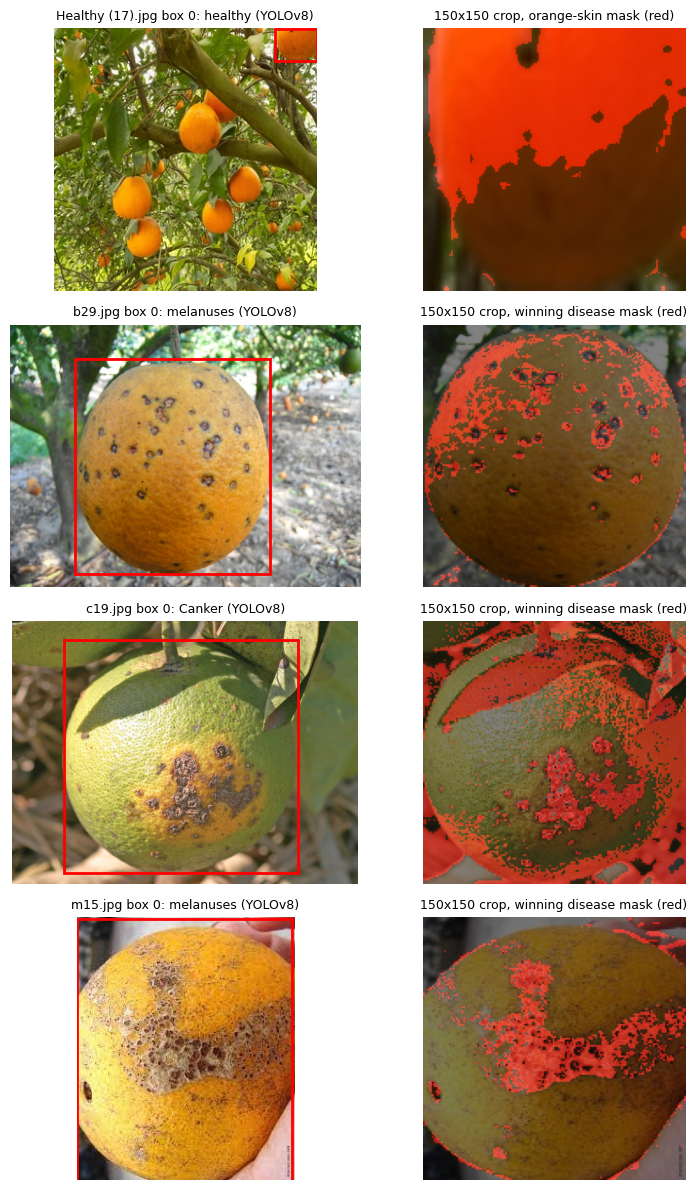

In [ ]:
import matplotlib.patches as patches

fig, axes = plt.subplots(len(all_records), 2, figsize=(8, 3 * max(len(all_records), 1)), squeeze=False)
for row, r in enumerate(all_records):
    bgr = cv2.imread(str(img_dir / r["image"]))
    ax = axes[row][0]
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax.add_patch(patches.Rectangle((r["x1"], r["y1"]), r["x2"] - r["x1"], r["y2"] - r["y1"],
                                   fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f'{r["image"]} box {r["box"]}: {r["diagnosis"]} (YOLOv8)', fontsize=9)
    ax.axis("off")

    ax = axes[row][1]
    ax.imshow(cv2.cvtColor(r["crop"], cv2.COLOR_BGR2RGB))
    if r["mask"] is not None:
        overlay = np.zeros_like(r["crop"]); overlay[:, :, 0] = r["mask"]
        ax.imshow(overlay, alpha=0.5)
    ax.set_title(f'150x150 crop, {"winning disease mask" if r["diagnosis"] != "healthy" else "orange-skin mask"} (red)', fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Results table and CSV export

A compact table of the diagnosis decisions with the author's pixel counts. The CSV is written to `/content/orange_disease_results.csv` so it can be downloaded from the Colab file browser.

**日本語**: 診断結果と著者の画素カウントを表にまとめ、CSV として保存します。

In [ ]:
import pandas as pd

df = pd.DataFrame([{
    "image": r["image"], "box": r["box"],
    "bbox_xyxy": f'({r["x1"]},{r["y1"]},{r["x2"]},{r["y2"]})',
    "diagnosis": r["diagnosis"],
    "orange_mask_pre": r["pre"], "orange_mask_post": r["post"],
    "canker_px": r["counts"]["canker"], "blackspot_px": r["counts"]["blackspot"],
    "melanosis_px": r["counts"]["melanosis"],
} for r in all_records])
display(df)
df.to_csv("/content/orange_disease_results.csv", index=False)
print("saved: /content/orange_disease_results.csv")

,image,box,bbox_xyxy,diagnosis,orange_mask_pre,orange_mask_post,canker_px,blackspot_px,melanosis_px
0,Healthy (17).jpg,0,"(215,0,256,31)",healthy,10317,9958,748,1363,467
1,b29.jpg,0,"(190,100,758,729)",melanuses,10346,9651,2379,2644,3013
2,c19.jpg,0,"(180,66,990,875)",Canker,5849,3787,10042,3961,3202
3,m15.jpg,0,"(0,1,202,247)",melanuses,13933,12983,1972,2747,3334


saved: /content/orange_disease_results.csv


## 9. Interpretation, differences from the paper, and validation record

- **What was validated**: the author's published inference branch (YOLOv8 detection + HSL color-spectrum diagnosis) runs end-to-end on a fresh Colab CPU runtime, on 4 of the repository's own sample images, with all thresholds taken verbatim from `orange fruit disease.py` at commit `94a9496`.
- **What this is NOT**: a single-batch run does not verify the paper's 97-image benchmark (92.2% overall accuracy) or its orchard deployment claims; the WSN hardware (Raspberry Pi, Zigbee/LoRa) is paper-only content with no code. Training of `yolo_orange.pt` is not documented in the repository.
- **Class context caveat**: the `c/b/m/Healthy` filename prefixes are inferred, not documented; treat per-image class expectations as informal only.
- **Adaptations**: single-pass batch instead of an hourly daemon loop; matplotlib instead of `cv2.imshow`; e-mail alerts left disabled as published. No scientific parameter was changed.

**日本語**: 本ノートブックは著者コードの推論分岐を CPU ランタイムで最小例として実行・検証したものであり、論文の 97 枚ベンチマーク精度や OR チャード展開の検証ではありません。クラス対応はファイル名からの推定にすぎません。変更点は常駐ループの単発化・matplotlib 描画・メール無効化のみです。

**References**
- Foroughi, A. et al., "An edge computing wireless sensor network for diagnosing orange fruit disease", *Cluster Computing* 28(5), 2025. DOI: 10.1007/s10586-024-04999-y
- Author code: https://github.com/ArmanForoughi/Diagnosing-types-of-orange-fruit-diseases-by-image-processing-and-YOLOv8 @ `94a949622ec22d96a3033fc73c41390dbe6dfc14` (MIT License)
- Jocher, G. et al., Ultralytics YOLOv8. https://github.com/ultralytics/ultralytics